In [1]:
# ========== SETUP + DATA ASSEMBLY (run this first) ==========
import pandas as pd
import numpy as np
from scipy import stats

REPO_FILE = "rbi_repo_rate_decision.xlsx"   # change to your path
CALL_FILE = "wacr.xlsx"                     # change to your path

# ---------- 1. Repo rate: clean ----------
repo = pd.read_excel(REPO_FILE, sheet_name="Sheet1")
repo["date"] = pd.to_datetime(repo["Date"], format="%b %d, %Y")
repo["repo"] = np.where(repo["Actual"] < 1, repo["Actual"] * 100, repo["Actual"])  # one unit: percent
repo = (repo[["date", "repo"]]
        .drop_duplicates(subset="date")      # two sources overlap 2013-2015
        .sort_values("date")
        .reset_index(drop=True))
repo["repo"] = repo["repo"].round(2)

# keep only actual changes
repo["repo_change"] = repo["repo"].diff().round(2)
changes = repo[repo["repo_change"].fillna(0) != 0].copy()

# start from 2001 (2000 values look like a different policy rate)
changes = changes[changes["date"] >= "2001-01-01"]

# drop Nov 2004 row: not a policy move, RBI swapped the names repo/reverse repo (Oct 2004)
changes = changes[changes["date"] != "2004-11-04"]

# add moves missing from the file (Oct 2006 - Nov 2008), dates = RBI announcement dates
missing = pd.DataFrame({
    "date": pd.to_datetime(["2006-10-31", "2007-01-31", "2007-03-30", "2008-06-11",
                            "2008-06-24", "2008-07-29", "2008-10-20", "2008-11-03"]),
    "repo_change": [0.25, 0.25, 0.25, 0.25, 0.50, 0.50, -1.00, -0.50],
})
changes = pd.concat([changes, missing]).sort_values("date").reset_index(drop=True)

# ---------- 2. Label announced / unannounced ----------
# Unannounced = off-cycle move, made between scheduled policy reviews
OFF_CYCLE_DATES = [
    # 2001-2003: LAF repo moves made outside the April policy / Oct-Nov mid-term review
    "2001-02-20", "2001-03-02", "2001-04-27", "2001-05-28",
    "2002-03-05", "2002-06-27", "2003-03-03", "2003-08-25",
    # 2006-2010
    "2006-06-09", "2007-03-30", "2008-06-11", "2008-06-24",
    "2008-10-20", "2008-11-03", "2008-12-08", "2009-01-02", "2009-03-04",
    "2010-03-22", "2010-07-05",
    # 2015 onwards
    "2015-01-15", "2015-03-04",
    "2020-03-27", "2020-05-22", "2022-05-04",
]
changes["announced"] = np.where(changes["date"].isin(pd.to_datetime(OFF_CYCLE_DATES)), 0, 1)

# ---------- 3. One event per month ----------
changes["month"] = changes["date"].dt.to_period("M")
events = (changes.groupby("month")
          .agg(date=("date", "first"),
               repo_change=("repo_change", "sum"),
               n_changes=("repo_change", "size"),
               announced=("announced", "min"))   # any off-cycle move in the month -> unannounced
          .reset_index())

# ---------- 4. Call money rate: monthly ----------
call = pd.read_excel(CALL_FILE)
call.columns = call.columns.str.strip()          # headers have stray spaces
call["month"] = pd.to_datetime(call["Period"]).dt.to_period("M")
call = call.set_index("month")["AVERAGE_RATE"]

# ---------- 5. Baseline (month before) and next month ----------
events["call_before"] = events["month"].map(lambda m: call.get(m - 1))
events["call_after"]  = events["month"].map(lambda m: call.get(m + 1))
events["call_change"] = events["call_after"] - events["call_before"]
events["pass_through"] = events["call_change"] / events["repo_change"]

# flag: another repo change in the next month would contaminate the measure
events["clean"] = (events["month"].shift(-1) != events["month"] + 1).astype(int)

df = events.dropna(subset=["call_before", "call_after"]).reset_index(drop=True)

df[["date", "repo_change", "announced", "clean", "pass_through"]].tail()

,date,repo_change,announced,clean,pass_through
65,2023-02-08,0.25,1,1,1.0416
66,2025-02-07,-0.25,1,1,1.1548
67,2025-04-09,-0.25,1,1,1.9632
68,2025-06-06,-0.50,1,1,0.8828
69,2025-12-05,-0.25,1,1,0.1248


In [2]:
# ---------- Label each change as expected / surprise (uses the Consensus column) ----------
raw = pd.read_excel(REPO_FILE, sheet_name="Sheet1")
raw["month"] = pd.to_datetime(raw["Date"], format="%b %d, %Y").dt.to_period("M")
raw["consensus"] = pd.to_numeric(raw["Consensus"], errors="coerce") * 100   # '-' becomes NaN
raw["actual"] = np.where(raw["Actual"] < 1, raw["Actual"] * 100, raw["Actual"])
raw = raw.dropna(subset=["consensus"])

# 1 = RBI did what the market forecast, 0 = it did something else
raw["expected"] = (raw["actual"].round(2) == raw["consensus"].round(2)).astype(int)
expected_by_month = raw.groupby("month")["expected"].min()

df["expected"] = df["month"].map(expected_by_month).fillna(0)   # no forecast available -> surprise
df.loc[df["announced"] == 0, "expected"] = 0     # off-cycle moves: nobody forecast them -> surprise

# keep ALL events (2001-2025); those without a Consensus forecast count as surprises
df_exp = df.copy()
df_exp["expected"] = df_exp["expected"].astype(int)

df_exp[["date", "repo_change", "expected", "clean", "pass_through"]]

,date,repo_change,expected,clean,pass_through
0,2001-02-20,-0.50,0,0,4.2200
1,2001-03-02,-0.50,0,0,2.0400
2,2001-04-27,-0.25,0,0,-1.0000
3,2001-05-28,-0.25,0,1,1.0000
4,2002-03-05,-0.50,0,1,0.3000
...,...,...,...,...,...
65,2023-02-08,0.25,1,1,1.0416
66,2025-02-07,-0.25,1,1,1.1548
67,2025-04-09,-0.25,1,1,1.9632
68,2025-06-06,-0.50,0,1,0.8828


In [3]:
def compare_by(data, col, label):
    a = data.loc[data[col] == 1, "pass_through"]     # expected
    u = data.loc[data[col] == 0, "pass_through"]     # surprise
    t = stats.ttest_ind(a, u, equal_var=False)
    m = stats.mannwhitneyu(a, u, alternative="two-sided")
    return {"sample": label,
            "n_expected": len(a), "n_surprise": len(u),
            "mean_expected": a.mean(), "mean_surprise": u.mean(),
            "median_expected": a.median(), "median_surprise": u.median(),
            "t_test_p": t.pvalue, "mann_whitney_p": m.pvalue}

results_exp = pd.DataFrame([
    compare_by(df_exp[df_exp["clean"] == 1], "expected", "Clean events (main test)"),
    compare_by(df_exp, "expected", "All events"),
]).set_index("sample")

results_exp.round(3).T

sample,Clean events (main test),All events
n_expected,15.000,15.000
n_surprise,39.000,55.000
mean_expected,1.249,1.249
mean_surprise,1.206,1.446
median_expected,1.173,1.173
median_surprise,1.103,1.320
t_test_p,0.906,0.564
mann_whitney_p,0.728,0.668


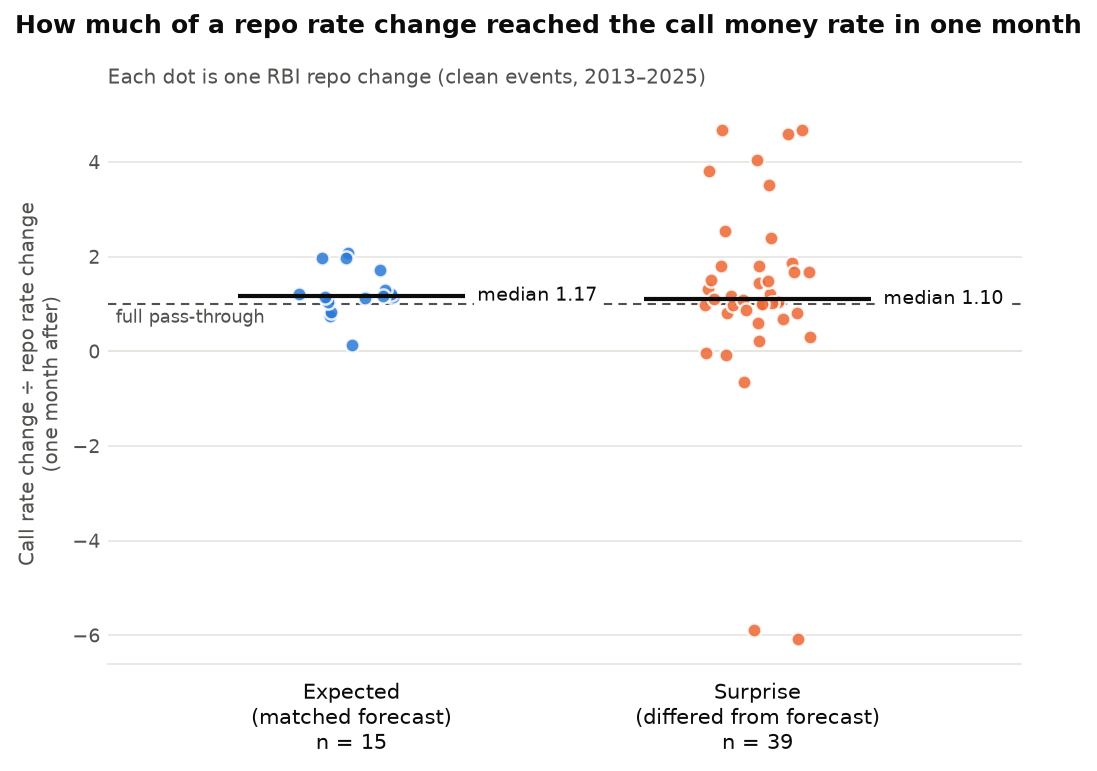

In [4]:
import matplotlib.pyplot as plt

BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e0"

GROUP_COL = "expected"            # or "announced" for the earlier plot
plot_df = df_exp[df_exp["clean"] == 1]
groups = [(1, "Expected\n(matched forecast)", BLUE),
          (0, "Surprise\n(differed from forecast)", ORANGE)]

fig, ax = plt.subplots(figsize=(7, 5.2), dpi=150)
rng = np.random.default_rng(7)

for x, (flag, name, color) in enumerate(groups):
    y = plot_df.loc[plot_df[GROUP_COL] == flag, "pass_through"]
    jitter = rng.uniform(-0.13, 0.13, len(y))
    ax.scatter(x + jitter, y, s=46, color=color, alpha=0.85,
               edgecolor="white", linewidth=1.2, zorder=3)
    med = y.median()
    ax.hlines(med, x - 0.28, x + 0.28, color=INK, linewidth=2, zorder=4)
    ax.text(x + 0.31, med, f"median {med:.2f}", va="center",
            fontsize=9, color=INK, zorder=5,
            bbox=dict(facecolor="white", edgecolor="none", pad=1.5))

# reference: full pass-through
ax.axhline(1, color=MUTED, linewidth=1, linestyle=(0, (4, 3)), zorder=2)
ax.text(-0.58, 0.9, "full pass-through", va="top", ha="left",
        fontsize=8.5, color=MUTED)
ax.axhline(0, color=GRID, linewidth=1, zorder=1)

counts = plot_df[GROUP_COL].value_counts()
ax.set_xticks([0, 1], [f"{name}\nn = {counts.get(flag, 0)}" for flag, name, _ in groups],
              fontsize=10, color=INK)
ax.set_xlim(-0.6, 1.65)
ax.set_ylabel("Call rate change ÷ repo rate change\n(one month after)",
              fontsize=9.5, color=MUTED)
ax.yaxis.grid(True, color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)
ax.tick_params(axis="y", colors=MUTED, labelsize=9, length=0)
ax.tick_params(axis="x", length=0, pad=8)

fig.suptitle("How much of a repo rate change reached the call money rate in one month",
             x=0.02, ha="left", fontsize=12, fontweight="bold", color=INK)
ax.set_title("Each dot is one RBI repo change (clean events, 2013–2025)",
             loc="left", fontsize=9.5, color=MUTED, pad=10)

fig.tight_layout()
plt.show()

In [5]:
# ---------- Daily net LAF liquidity (outstanding, Rs crore) ----------
LAF_FILE = "Daily_LAF_Operation.xlsx"   # change to your path

laf = pd.read_excel(LAF_FILE, header=None, skiprows=6).iloc[:, 1:]
laf.columns = ["date",
               "fix_period", "fix_repo_bids_n", "fix_repo_bids_amt", "fix_repo_acc_n", "fix_repo_amt", "fix_repo_rate",
               "fix_rr_bids_n", "fix_rr_bids_amt", "fix_rr_acc_n", "fix_rr_amt", "fix_rr_rate",
               "var_repo_period", "var_repo_bids_n", "var_repo_bids_amt", "var_repo_acc_n", "var_repo_amt", "var_repo_rate",
               "var_rr_period", "var_rr_bids_n", "var_rr_bids_amt", "var_rr_acc_n", "var_rr_amt", "var_rr_rate"]
laf["date"] = pd.to_datetime(laf["date"], errors="coerce")
laf = laf.dropna(subset=["date"])                       # drops year headers and footnotes

num = ["fix_period", "fix_repo_amt", "fix_rr_amt", "var_repo_period", "var_repo_amt", "var_rr_period", "var_rr_amt"]
laf[num] = laf[num].apply(pd.to_numeric, errors="coerce")

# before Oct 29, 2004 the names were swapped: "repo" = absorption, "reverse repo" = injection
old = laf["date"] < "2004-10-29"
laf.loc[old, ["fix_repo_amt", "fix_rr_amt"]] = laf.loc[old, ["fix_rr_amt", "fix_repo_amt"]].values

# one row per operation: amount (+ inject, - absorb) and tenor in days
ops = pd.concat([
    pd.DataFrame({"date": laf["date"], "amt":  laf["fix_repo_amt"], "days": laf["fix_period"]}),
    pd.DataFrame({"date": laf["date"], "amt": -laf["fix_rr_amt"],   "days": laf["fix_period"]}),
    pd.DataFrame({"date": laf["date"], "amt":  laf["var_repo_amt"], "days": laf["var_repo_period"]}),
    pd.DataFrame({"date": laf["date"], "amt": -laf["var_rr_amt"],   "days": laf["var_rr_period"]}),
])
ops = ops[ops["amt"].fillna(0) != 0].copy()
ops["days"] = ops["days"].fillna(1).clip(lower=1)

# each operation stays outstanding from its date until it matures
cal = pd.date_range(ops["date"].min(), ops["date"].max() + pd.Timedelta(days=60))
flow = pd.Series(0.0, index=cal)
start = ops.groupby("date")["amt"].sum()
end = ops.assign(end=ops["date"] + pd.to_timedelta(ops["days"], unit="D")).groupby("end")["amt"].sum()
flow = flow.add(start, fill_value=0).sub(end, fill_value=0)
net_liq = flow.cumsum()          # + = RBI is net lending to banks, - = net absorbing

net_liq.loc["2013":].resample("ME").mean().div(1e5).round(2).tail(12)   # Rs lakh crore, quick sanity check

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
/var/folders/m0/qdbbsmdx5hb2f8pnz60x2jww0000gn/T/ipykernel_72147/725747396.py:10: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  laf["date"] = pd.to_datetime(laf["date"], errors="coerce")


2026-01-31    0.60
2026-02-28    1.37
2026-03-31    1.74
2026-04-30    0.44
2026-05-31    0.40
2026-06-30    0.78
2026-07-31    0.41
2026-08-31   -1.66
2026-09-30   -6.22
2026-10-31   -1.05
2026-11-30    0.00
2026-12-31    0.00
Freq: ME, dtype: float64

In [6]:
# ---------- Liquidity change around each repo decision ----------
WINDOW = 14                        # calendar days before / after the decision
END = "2022-03-31"                 # after this, SDF absorption is missing from the LAF file

ev = df_exp[df_exp["date"] <= END][["date", "repo_change", "expected"]].copy()
ev["move"] = np.where(ev["repo_change"] < 0, "cut", "hike")
ev["size_25bp"] = ev["repo_change"].abs() / 0.25

def window_mean(d, lo, hi):
    return net_liq.loc[d + pd.Timedelta(days=lo): d + pd.Timedelta(days=hi)].mean()

ev["liq_before"] = ev["date"].map(lambda d: window_mean(d, -WINDOW, -1))
ev["liq_after"]  = ev["date"].map(lambda d: window_mean(d, 1, WINDOW))
ev["liq_change"] = ev["liq_after"] - ev["liq_before"]          # Rs crore

# in the policy direction, per 25 bp: + = more injection after a cut / more absorption after a hike
ev["liq_effect"] = np.where(ev["move"] == "cut", ev["liq_change"], -ev["liq_change"]) / ev["size_25bp"]

ev["label"] = np.where(ev["expected"] == 1, "expected", "surprise")
ev = ev.dropna(subset=["liq_effect"])
ev.groupby(["move", "label"]).size()

move  label   
cut   expected     8
      surprise    23
hike  expected     1
      surprise    26
dtype: int64

In [7]:
# ---------- Test: cuts (enough events) and hikes (describe only) ----------
def liq_compare(data, label):
    e = data.loc[data["expected"] == 1, "liq_effect"]
    s = data.loc[data["expected"] == 0, "liq_effect"]
    out = {"sample": label, "n_expected": len(e), "n_surprise": len(s),
           "median_expected": e.median(), "median_surprise": s.median(),
           "mean_expected": e.mean(), "mean_surprise": s.mean()}
    if min(len(e), len(s)) >= 3:
        out["t_test_p"] = stats.ttest_ind(e, s, equal_var=False).pvalue
        out["mann_whitney_p"] = stats.mannwhitneyu(e, s, alternative="two-sided").pvalue
    return out

cuts, hikes = ev[ev["move"] == "cut"], ev[ev["move"] == "hike"]
liq_results = pd.DataFrame([
    liq_compare(cuts, "Cuts (main test)"),
    liq_compare(cuts[cuts["date"].dt.year != 2020], "Cuts, excl. COVID 2020"),
    liq_compare(hikes, "Hikes (too few to test)"),
]).set_index("sample")

print("liq_effect = Rs crore per 25 bp, in the policy direction")
liq_results.round(3).T

liq_effect = Rs crore per 25 bp, in the policy direction


sample,Cuts (main test),"Cuts, excl. COVID 2020",Hikes (too few to test)
n_expected,8.000,8.000,1.000
n_surprise,23.000,21.000,26.000
median_expected,-19909.786,-19909.786,63087.500
median_surprise,554.464,554.464,-5773.155
mean_expected,-33136.286,-33136.286,63087.500
mean_surprise,5049.717,5394.159,-4998.425
t_test_p,0.095,0.090,NaN
mann_whitney_p,0.018,0.016,NaN


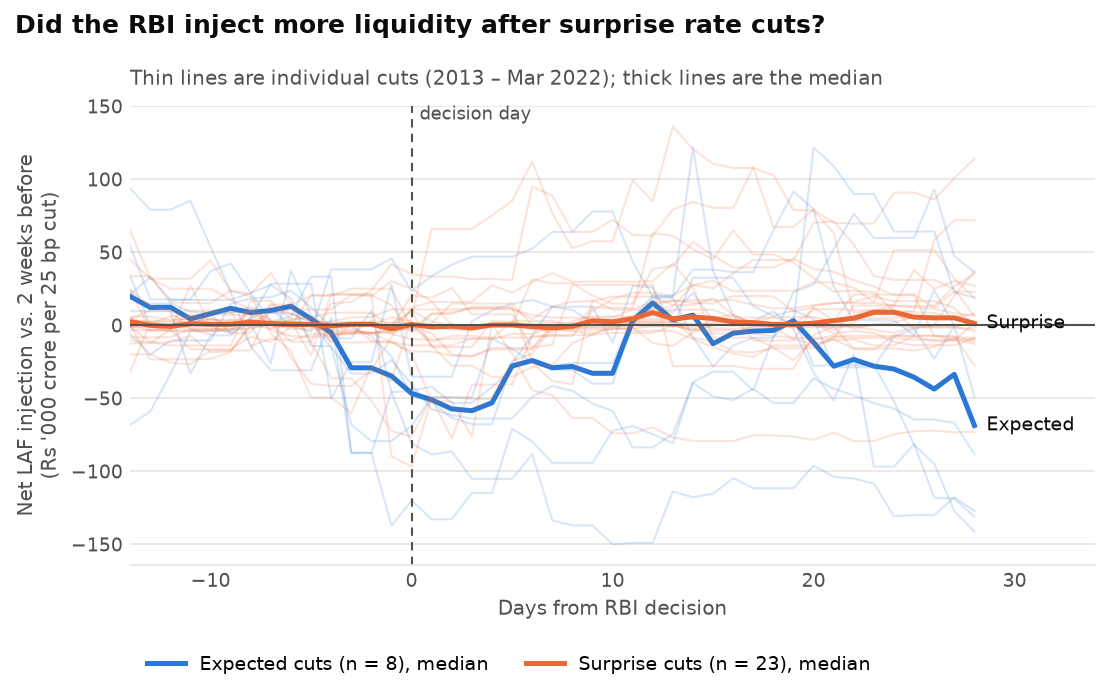

In [8]:
import matplotlib.pyplot as plt

BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e0"
DAYS = np.arange(-WINDOW, 2 * WINDOW + 1)

def path(row):
    """Net liquidity vs. the pre-decision average, per 25 bp, in Rs '000 crore."""
    s = net_liq.reindex(row["date"] + pd.to_timedelta(DAYS, unit="D")).values
    return (s - row["liq_before"]) / row["size_25bp"] / 1e3

fig, ax = plt.subplots(figsize=(7.5, 4.8), dpi=150)

for label, color, name in [("expected", BLUE, "Expected cuts"), ("surprise", ORANGE, "Surprise cuts")]:
    rows = cuts[cuts["label"] == label]
    paths = np.vstack([path(r) for _, r in rows.iterrows()])
    for p in paths:
        ax.plot(DAYS, p, color=color, alpha=0.18, linewidth=1)
    med = np.median(paths, axis=0)
    ax.plot(DAYS, med, color=color, linewidth=2.4, label=f"{name} (n = {len(rows)}), median")
    ax.text(DAYS[-1] + 0.6, med[-1], name.split()[0], color=INK, fontsize=9, va="center")

ax.axhline(0, color=MUTED, linewidth=1)
ax.axvline(0, color=MUTED, linewidth=1, linestyle=(0, (4, 3)))
ax.text(0.4, 1.0, "decision day", transform=ax.get_xaxis_transform(),
        va="top", fontsize=8.5, color=MUTED)

ax.set_xlim(DAYS[0], DAYS[-1] + 6)
ax.set_xlabel("Days from RBI decision", fontsize=9.5, color=MUTED)
ax.set_ylabel("Net LAF injection vs. 2 weeks before\n(Rs '000 crore per 25 bp cut)", fontsize=9.5, color=MUTED)
ax.yaxis.grid(True, color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)
ax.tick_params(colors=MUTED, labelsize=9, length=0)
ax.legend(frameon=False, fontsize=9, loc="upper left", bbox_to_anchor=(0, -0.16), ncol=2)

fig.suptitle("Did the RBI inject more liquidity after surprise rate cuts?",
             x=0.02, ha="left", fontsize=12, fontweight="bold", color=INK)
ax.set_title("Thin lines are individual cuts (2013 – Mar 2022); thick lines are the median",
             loc="left", fontsize=9.5, color=MUTED, pad=10)

fig.tight_layout()
plt.show()

In [9]:
# ---------- Split: bank-chosen (fixed-rate) vs RBI-chosen (variable-rate) liquidity ----------
ops_all = pd.concat([
    pd.DataFrame({"date": laf["date"], "amt":  laf["fix_repo_amt"], "days": laf["fix_period"],      "kind": "fixed"}),
    pd.DataFrame({"date": laf["date"], "amt": -laf["fix_rr_amt"],   "days": laf["fix_period"],      "kind": "fixed"}),
    pd.DataFrame({"date": laf["date"], "amt":  laf["var_repo_amt"], "days": laf["var_repo_period"], "kind": "variable"}),
    pd.DataFrame({"date": laf["date"], "amt": -laf["var_rr_amt"],   "days": laf["var_rr_period"],   "kind": "variable"}),
])
ops_all = ops_all[ops_all["amt"].fillna(0) != 0].copy()
ops_all["days"] = ops_all["days"].fillna(1).clip(lower=1)

def outstanding(o):
    """Daily outstanding amount of a set of operations (Rs crore)."""
    f = pd.Series(0.0, index=cal)
    f = f.add(o.groupby("date")["amt"].sum(), fill_value=0)
    f = f.sub(o.assign(end=o["date"] + pd.to_timedelta(o["days"], unit="D")).groupby("end")["amt"].sum(), fill_value=0)
    return f.cumsum()

liq_parts = {
    "fixed":    outstanding(ops_all[ops_all["kind"] == "fixed"]),      # banks choose the amount
    "variable": outstanding(ops_all[ops_all["kind"] == "variable"]),   # RBI sets the maximum amount
}

cuts = cuts.copy()

# liquidity effect per 25 bp (policy direction) for each part, same windows as before
for part, s in liq_parts.items():
    before = cuts["date"].map(lambda d: s.loc[d - pd.Timedelta(days=WINDOW): d - pd.Timedelta(days=1)].mean())
    after  = cuts["date"].map(lambda d: s.loc[d + pd.Timedelta(days=1): d + pd.Timedelta(days=WINDOW)].mean())
    cuts[f"effect_{part}"] = (after - before) / cuts["size_25bp"]

def split_compare(data, col, label):
    e = data.loc[data["expected"] == 1, col]
    s = data.loc[data["expected"] == 0, col]
    return {"sample": label, "n_expected": len(e), "n_surprise": len(s),
            "median_expected": e.median(), "median_surprise": s.median(),
            "mann_whitney_p": stats.mannwhitneyu(e, s, alternative="two-sided").pvalue}

split_results = pd.DataFrame([
    split_compare(cuts, "effect_fixed",    "Fixed-rate (banks choose)"),
    split_compare(cuts, "effect_variable", "Variable-rate (RBI sets the cap)"),
    split_compare(cuts, "liq_effect",      "Total (as before)"),
]).set_index("sample")

print("Rs crore per 25 bp cut; + = more injection after the cut")
split_results.round(3).T

Rs crore per 25 bp cut; + = more injection after the cut


sample,Fixed-rate (banks choose),Variable-rate (RBI sets the cap),Total (as before)
n_expected,8.000,8.000,8.000
n_surprise,23.000,23.000,23.000
median_expected,9330.714,-37687.214,-19909.786
median_surprise,1239.107,0.000,554.464
mann_whitney_p,0.132,0.001,0.018


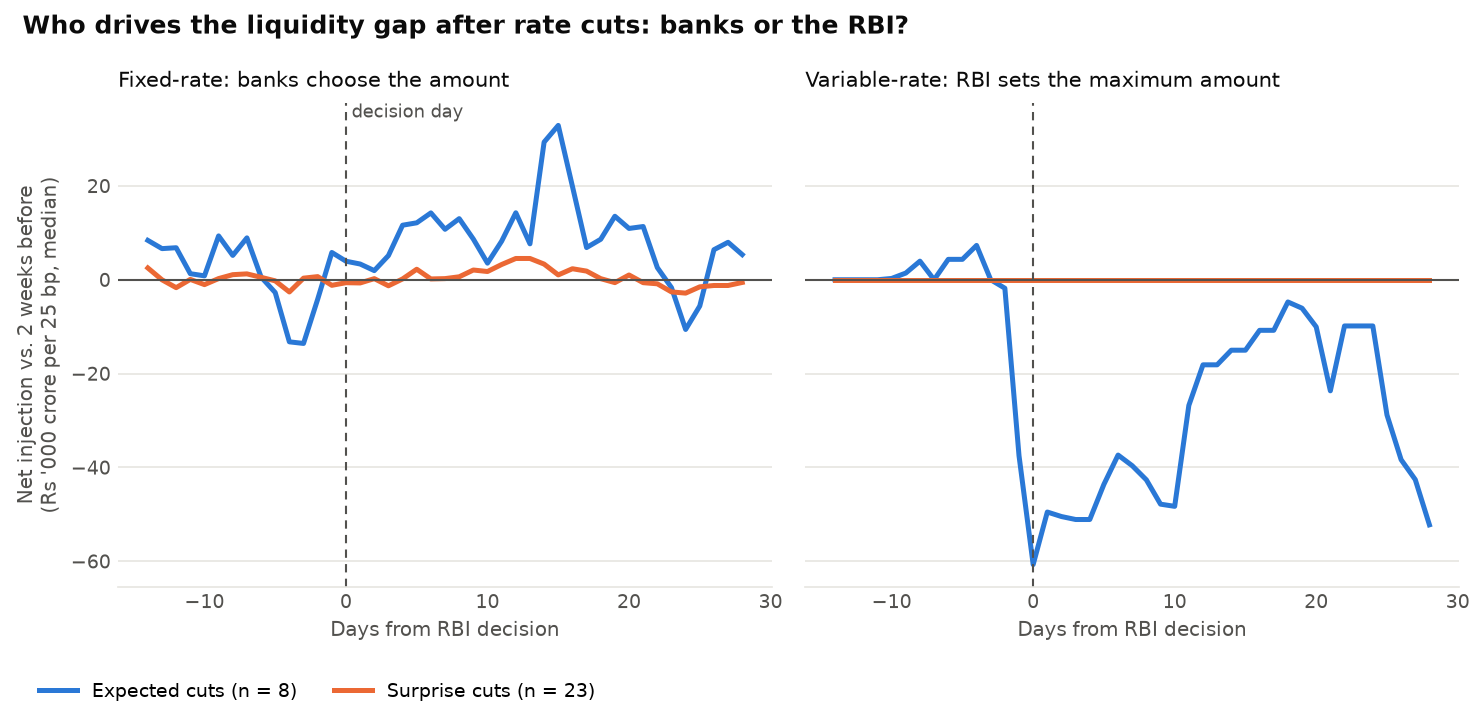

In [10]:
import matplotlib.pyplot as plt

BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e0"
DAYS = np.arange(-WINDOW, 2 * WINDOW + 1)

def part_path(s, row):
    base = s.loc[row["date"] - pd.Timedelta(days=WINDOW): row["date"] - pd.Timedelta(days=1)].mean()
    return (s.reindex(row["date"] + pd.to_timedelta(DAYS, unit="D")).values - base) / row["size_25bp"] / 1e3

fig, axes = plt.subplots(1, 2, figsize=(10, 4.6), dpi=150, sharey=True)
titles = {"fixed": "Fixed-rate: banks choose the amount",
          "variable": "Variable-rate: RBI sets the maximum amount"}

for ax, part in zip(axes, ["fixed", "variable"]):
    s = liq_parts[part]
    for label, color, name in [("expected", BLUE, "Expected"), ("surprise", ORANGE, "Surprise")]:
        rows = cuts[cuts["label"] == label]
        paths = np.vstack([part_path(s, r) for _, r in rows.iterrows()])
        ax.plot(DAYS, np.median(paths, axis=0), color=color, linewidth=2.4,
                label=f"{name} cuts (n = {len(rows)})")
    ax.axhline(0, color=MUTED, linewidth=1)
    ax.axvline(0, color=MUTED, linewidth=1, linestyle=(0, (4, 3)))
    ax.set_title(titles[part], loc="left", fontsize=10, color=INK, pad=8)
    ax.set_xlabel("Days from RBI decision", fontsize=9.5, color=MUTED)
    ax.yaxis.grid(True, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
    ax.tick_params(colors=MUTED, labelsize=9, length=0)

axes[0].set_ylabel("Net injection vs. 2 weeks before\n(Rs '000 crore per 25 bp, median)", fontsize=9.5, color=MUTED)
axes[0].text(0.4, 1.0, "decision day", transform=axes[0].get_xaxis_transform(), va="top", fontsize=8.5, color=MUTED)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, frameon=False, fontsize=9, loc="lower left", ncol=2, bbox_to_anchor=(0.02, -0.04))

fig.suptitle("Who drives the liquidity gap after rate cuts: banks or the RBI?",
             x=0.02, ha="left", fontsize=12, fontweight="bold", color=INK)
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

In [11]:
# share of variable-rate repo auctions where every bid was accepted
# (= banks asked for less than the RBI offered, so bank demand set the amount)
v = laf[laf["date"].between("2013-01-01", END) & (laf["var_repo_amt"] > 0)].copy()
v["var_repo_bids_amt"] = pd.to_numeric(v["var_repo_bids_amt"], errors="coerce")
(v["var_repo_amt"] >= v["var_repo_bids_amt"]).mean()

np.float64(0.5640138408304498)

In [12]:
# ---------- Bank demand: bids received vs amounts accepted in variable-rate (term) operations ----------
for c in ["var_repo_bids_amt", "var_rr_bids_amt"]:
    laf[c] = pd.to_numeric(laf[c], errors="coerce")

def ops_from(amt_col, period_col):
    o = pd.DataFrame({"date": laf["date"], "amt": laf[amt_col], "days": laf[period_col]})
    o = o[o["amt"].fillna(0) > 0].copy()
    o["days"] = o["days"].fillna(1).clip(lower=1)
    return o

# each series counted for the tenor asked, so it is comparable with the earlier outstanding measure
term = {
    "repo_bids":     outstanding(ops_from("var_repo_bids_amt", "var_repo_period")),  # banks asking to BORROW
    "repo_accepted": outstanding(ops_from("var_repo_amt",      "var_repo_period")),
    "rr_bids":       outstanding(ops_from("var_rr_bids_amt",   "var_rr_period")),    # banks offering to PARK cash
    "rr_accepted":   outstanding(ops_from("var_rr_amt",        "var_rr_period")),
}

ev_term = cuts[cuts["date"] >= "2013-10-01"].copy()     # variable-rate term operations start Oct 2013

for name, s in term.items():
    before = ev_term["date"].map(lambda d: s.loc[d - pd.Timedelta(days=WINDOW): d - pd.Timedelta(days=1)].mean())
    after  = ev_term["date"].map(lambda d: s.loc[d + pd.Timedelta(days=1): d + pd.Timedelta(days=WINDOW)].mean())
    ev_term[name] = (after - before) / ev_term["size_25bp"]

bids_results = pd.DataFrame([split_compare(ev_term, n, n) for n in term]).set_index("sample")
bids_results.index = ["Term repo: bids (banks want to borrow)", "Term repo: accepted",
                      "Term reverse repo: bids (banks want to park cash)", "Term reverse repo: accepted"]

print("Change after vs before, Rs crore per 25 bp cut (+ = higher after the cut)")
bids_results.round(3).T

Change after vs before, Rs crore per 25 bp cut (+ = higher after the cut)


,Term repo: bids (banks want to borrow),Term repo: accepted,Term reverse repo: bids (banks want to park cash),Term reverse repo: accepted
n_expected,6.000,6.000,6.000,6.000
n_surprise,8.000,8.000,8.000,8.000
median_expected,-31646.071,-30760.000,18517.857,16892.536
median_surprise,-507.679,-808.393,-3038.595,-2807.631
mann_whitney_p,0.020,0.020,0.014,0.010


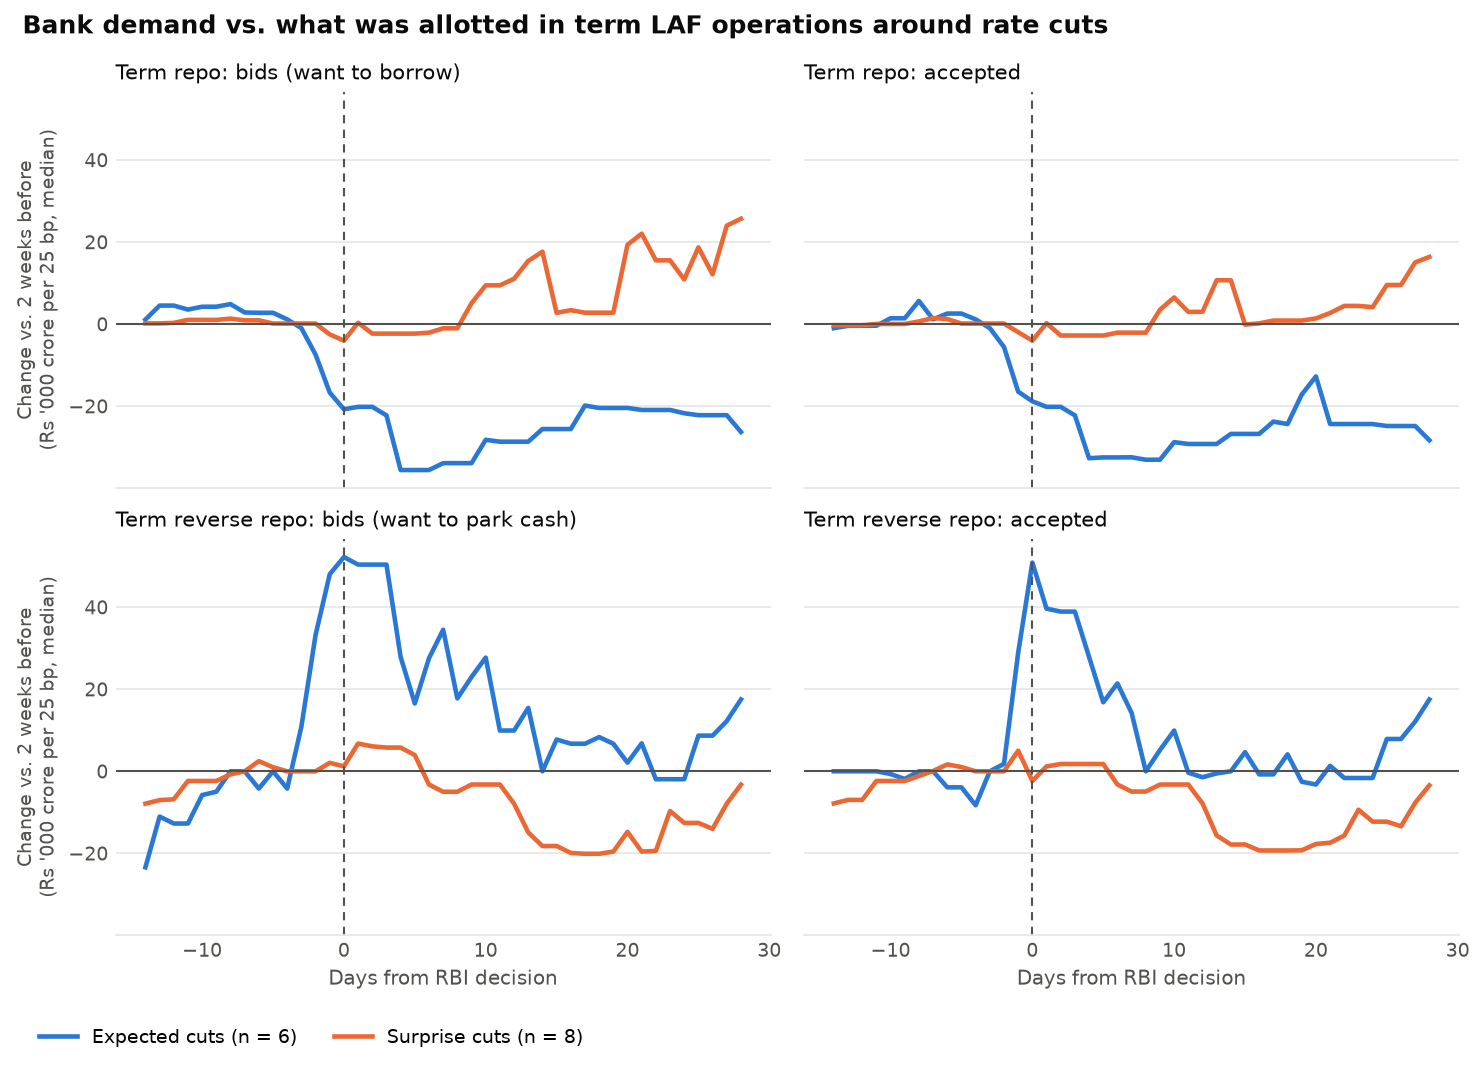

In [13]:
import matplotlib.pyplot as plt

BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e0"
DAYS = np.arange(-WINDOW, 2 * WINDOW + 1)

panels = [("repo_bids", "Term repo: bids (want to borrow)"),
          ("repo_accepted", "Term repo: accepted"),
          ("rr_bids", "Term reverse repo: bids (want to park cash)"),
          ("rr_accepted", "Term reverse repo: accepted")]

fig, axes = plt.subplots(2, 2, figsize=(10, 7), dpi=150, sharex=True, sharey=True)

for ax, (key, title) in zip(axes.flat, panels):
    s = term[key]
    for label, color, name in [("expected", BLUE, "Expected"), ("surprise", ORANGE, "Surprise")]:
        rows = ev_term[ev_term["label"] == label]
        paths = np.vstack([part_path(s, r) for _, r in rows.iterrows()])
        ax.plot(DAYS, np.median(paths, axis=0), color=color, linewidth=2.2,
                label=f"{name} cuts (n = {len(rows)})")
    ax.axhline(0, color=MUTED, linewidth=1)
    ax.axvline(0, color=MUTED, linewidth=1, linestyle=(0, (4, 3)))
    ax.set_title(title, loc="left", fontsize=10, color=INK, pad=6)
    ax.yaxis.grid(True, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
    ax.tick_params(colors=MUTED, labelsize=9, length=0)

for ax in axes[1]:
    ax.set_xlabel("Days from RBI decision", fontsize=9.5, color=MUTED)
for ax in axes[:, 0]:
    ax.set_ylabel("Change vs. 2 weeks before\n(Rs '000 crore per 25 bp, median)", fontsize=9, color=MUTED)

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, frameon=False, fontsize=9, loc="lower left", ncol=2, bbox_to_anchor=(0.02, -0.02))
fig.suptitle("Bank demand vs. what was allotted in term LAF operations around rate cuts",
             x=0.02, ha="left", fontsize=12, fontweight="bold", color=INK)
fig.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

In [14]:
# ---------- Mirror test: hikes + out-of-sample events (term operations only, Oct 2013 onwards) ----------
ev_all = df_exp[df_exp["date"] >= "2013-10-01"][["date", "repo_change", "expected"]].copy()
ev_all["move"] = np.where(ev_all["repo_change"] < 0, "cut", "hike")
ev_all["size_25bp"] = ev_all["repo_change"].abs() / 0.25
ev_all["label"] = np.where(ev_all["expected"] == 1, "expected", "surprise")
ev_all["sample"] = np.where(ev_all["date"] <= "2022-03-31", "original", "new (2022+)")

for name in ["repo_bids", "rr_bids"]:
    s = term[name]
    before = ev_all["date"].map(lambda d: s.loc[d - pd.Timedelta(days=WINDOW): d - pd.Timedelta(days=1)].mean())
    after  = ev_all["date"].map(lambda d: s.loc[d + pd.Timedelta(days=1): d + pd.Timedelta(days=WINDOW)].mean())
    ev_all[name] = (after - before) / ev_all["size_25bp"]

# Positioning score: shift toward borrowing (+) or parking (-), signed by the move.
# Anticipation predicts a POSITIVE score for expected moves:
#   expected cut  -> borrow less, park more  -> tilt < 0, x (-1) -> score > 0
#   expected hike -> borrow more, park less  -> tilt > 0, x (+1) -> score > 0
ev_all["positioning"] = (ev_all["repo_bids"] - ev_all["rr_bids"]) * np.sign(ev_all["repo_change"])

hikes_all = ev_all[ev_all["move"] == "hike"]
mirror = pd.DataFrame([
    split_compare(hikes_all, "repo_bids",   "Hikes: borrowing bids (predict expected > surprise)"),
    split_compare(hikes_all, "rr_bids",     "Hikes: parking bids (predict expected < surprise)"),
    split_compare(hikes_all, "positioning", "Hikes: positioning score"),
    split_compare(ev_all[ev_all["move"] == "cut"], "positioning", "Cuts: positioning score"),
    split_compare(ev_all, "positioning",    "All moves pooled: positioning score"),
]).set_index("sample")

print("Rs crore per 25 bp; positioning > 0 = banks moved the way anticipation predicts")
display(ev_all.groupby(["move", "label", "sample"]).size().unstack(fill_value=0))
mirror.round(3).T

Rs crore per 25 bp; positioning > 0 = banks moved the way anticipation predicts


sample         new (2022+)  original
move label                          
cut  expected            3         6
     surprise            1         8
hike expected            3         1
     surprise            3         3

sample,Hikes: borrowing bids (predict expected > surprise),Hikes: parking bids (predict expected < surprise),Hikes: positioning score,Cuts: positioning score,All moves pooled: positioning score
n_expected,4.000,4.000,4.000,9.000,13.000
n_surprise,6.000,6.000,6.000,9.000,15.000
median_expected,-1683.339,-11535.227,9851.888,98013.143,50113.786
median_surprise,1238.929,-17346.143,17794.536,0.000,8503.571
mann_whitney_p,0.746,0.748,0.476,0.022,0.065


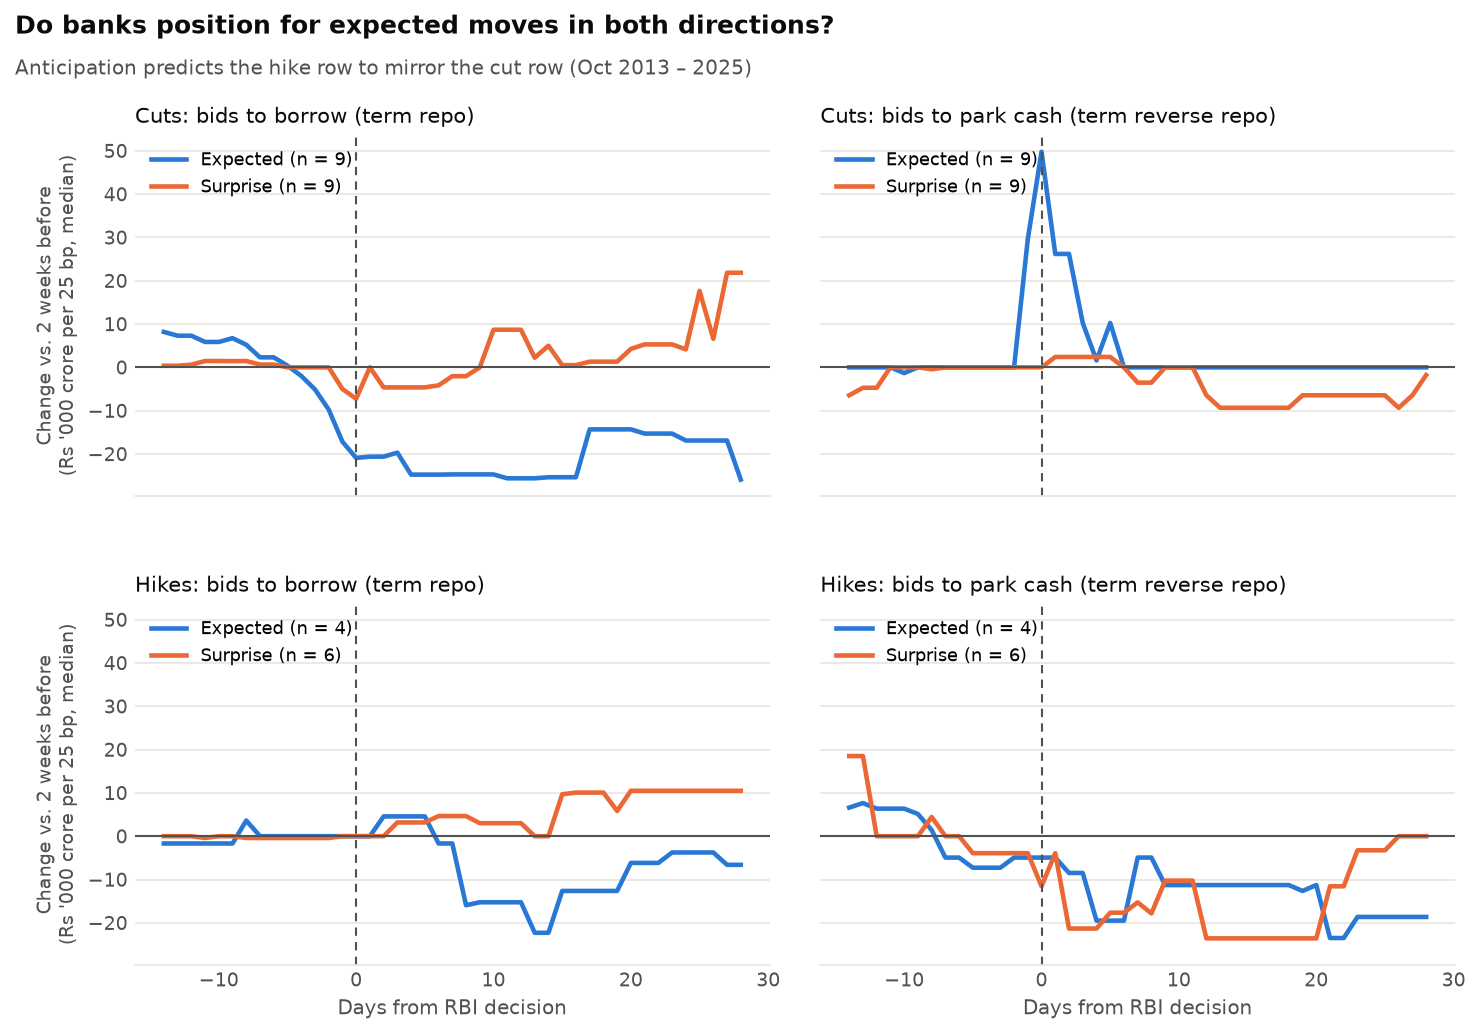

In [15]:
import matplotlib.pyplot as plt

BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e0"
DAYS = np.arange(-WINDOW, 2 * WINDOW + 1)

fig, axes = plt.subplots(2, 2, figsize=(10, 7), dpi=150, sharex=True, sharey=True)
layout = [("cut",  "repo_bids", "Cuts: bids to borrow (term repo)"),
          ("cut",  "rr_bids",   "Cuts: bids to park cash (term reverse repo)"),
          ("hike", "repo_bids", "Hikes: bids to borrow (term repo)"),
          ("hike", "rr_bids",   "Hikes: bids to park cash (term reverse repo)")]

for ax, (move, key, title) in zip(axes.flat, layout):
    s = term[key]
    for label, color, name in [("expected", BLUE, "Expected"), ("surprise", ORANGE, "Surprise")]:
        rows = ev_all[(ev_all["move"] == move) & (ev_all["label"] == label)]
        paths = np.vstack([part_path(s, r) for _, r in rows.iterrows()])
        ax.plot(DAYS, np.median(paths, axis=0), color=color, linewidth=2.2,
                label=f"{name} (n = {len(rows)})")
    ax.axhline(0, color=MUTED, linewidth=1)
    ax.axvline(0, color=MUTED, linewidth=1, linestyle=(0, (4, 3)))
    ax.set_title(title, loc="left", fontsize=10, color=INK, pad=6)
    ax.legend(frameon=False, fontsize=8.5, loc="upper left")
    ax.yaxis.grid(True, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
    ax.tick_params(colors=MUTED, labelsize=9, length=0)

for ax in axes[1]:
    ax.set_xlabel("Days from RBI decision", fontsize=9.5, color=MUTED)
for ax in axes[:, 0]:
    ax.set_ylabel("Change vs. 2 weeks before\n(Rs '000 crore per 25 bp, median)", fontsize=9, color=MUTED)

fig.suptitle("Do banks position for expected moves in both directions?",
             x=0.02, y=0.985, ha="left", fontsize=12, fontweight="bold", color=INK)
fig.text(0.02, 0.928, "Anticipation predicts the hike row to mirror the cut row (Oct 2013 – 2025)",
         ha="left", fontsize=9.5, color=MUTED)
fig.subplots_adjust(left=0.1, right=0.98, bottom=0.08, top=0.87, hspace=0.3, wspace=0.08)
plt.show()